# Projet 06 — Analyse du Profil des Vins : ACP
**Auteur :** Steven Barde  
**Date :** 2026-10-18  
**Dataset :** Wine Quality Dataset — UCI Machine Learning Repository  

## Objectif
Réduire la dimensionnalité des données chimiques du vin via l'Analyse en Composantes Principales (ACP) pour identifier les axes de différenciation et visualiser les groupes en 2D et 3D.

In [3]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
print("Librairies chargées ✓")

Librairies chargées ✓


## 1. Chargement et Exploration des Données

In [4]:
# Chargement (séparateur point-virgule)
df = pd.read_csv('../dataset/winequality-red.csv', sep=';')
print(f"Dimensions : {df.shape}")
print(f"\nColonnes : {list(df.columns)}")
df.head()

Dimensions : (1599, 12)

Colonnes : ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. Statistiques Descriptives et Nettoyage

In [5]:
# Statistiques descriptives
print("=== Statistiques descriptives ===")
print(df.describe().round(2))
print(f"\nValeurs manquantes : {df.isnull().sum().sum()}")
print(f"\nDistribution de la qualité :")
print(df['quality'].value_counts().sort_index())

=== Statistiques descriptives ===
       fixed acidity  volatile acidity  citric acid  residual sugar  \
count        1599.00           1599.00      1599.00         1599.00   
mean            8.32              0.53         0.27            2.54   
std             1.74              0.18         0.19            1.41   
min             4.60              0.12         0.00            0.90   
25%             7.10              0.39         0.09            1.90   
50%             7.90              0.52         0.26            2.20   
75%             9.20              0.64         0.42            2.60   
max            15.90              1.58         1.00           15.50   

       chlorides  free sulfur dioxide  total sulfur dioxide  density       pH  \
count    1599.00              1599.00               1599.00  1599.00  1599.00   
mean        0.09                15.87                 46.47     1.00     3.31   
std         0.05                10.46                 32.90     0.00     0.15   
mi

## 3. Visualisation des Distributions

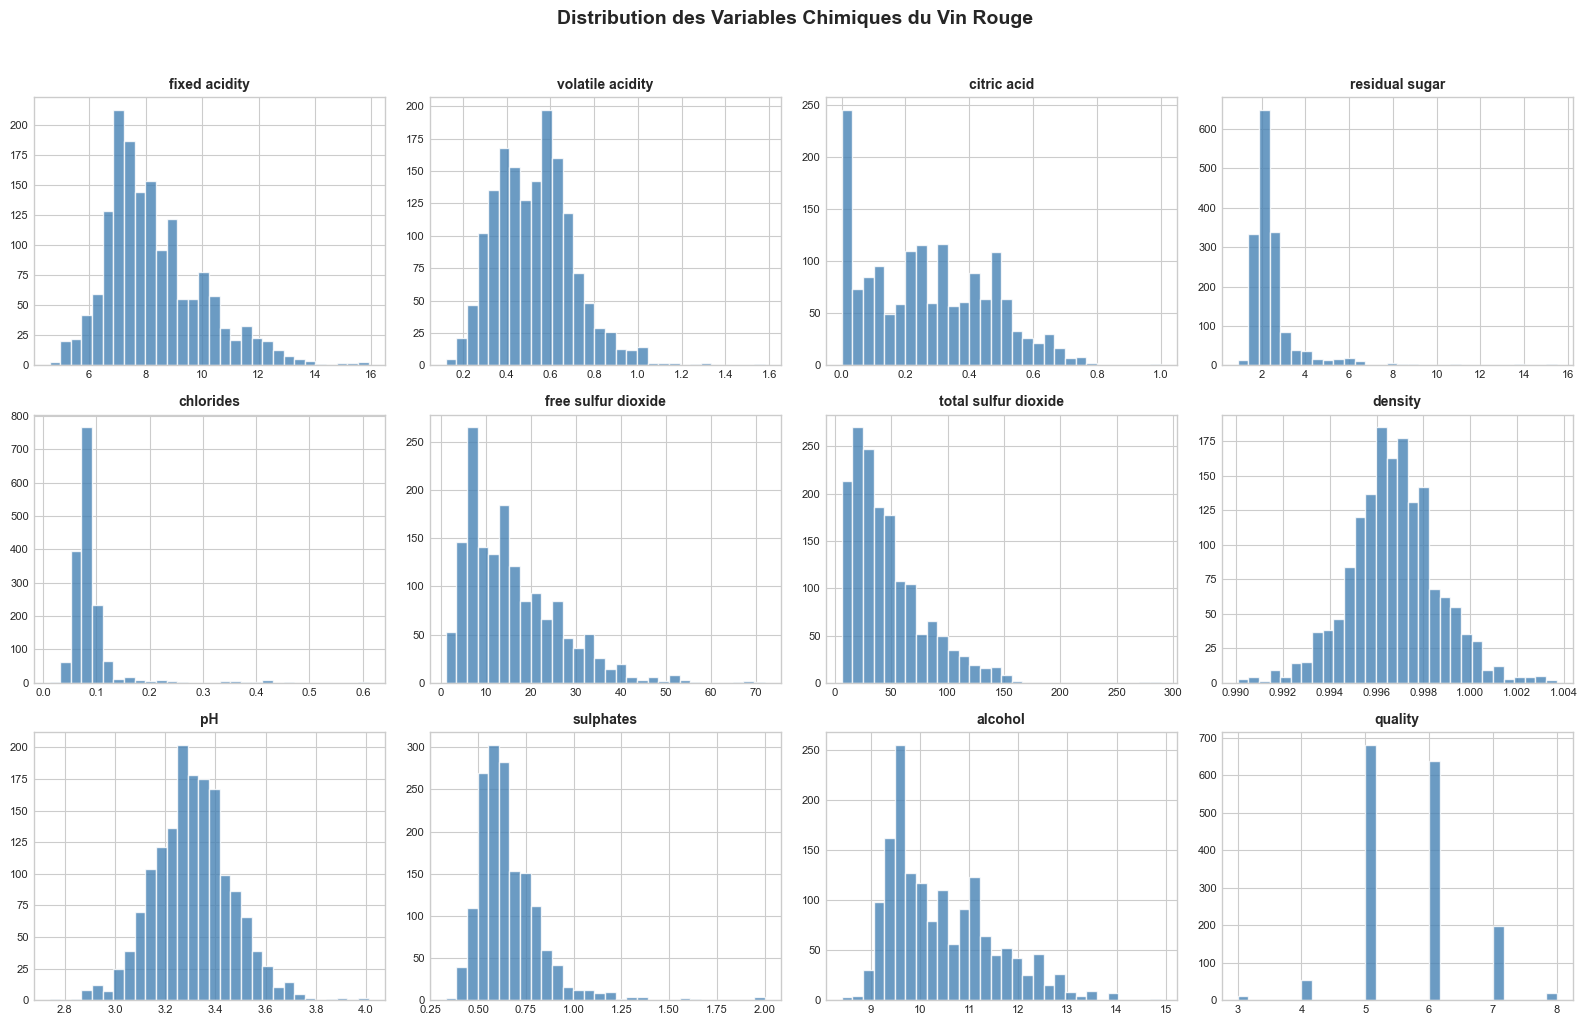

✓ Sauvegardé : 01_distributions.png


In [6]:
# Distribution des variables chimiques
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(df.columns):
    axes[i].hist(df[col], bins=30, color='steelblue', edgecolor='white', alpha=0.8)
    axes[i].set_title(col, fontsize=10, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].tick_params(labelsize=8)

plt.suptitle('Distribution des Variables Chimiques du Vin Rouge', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../images/01_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Sauvegardé : 01_distributions.png")

## 4. Matrice de Corrélation

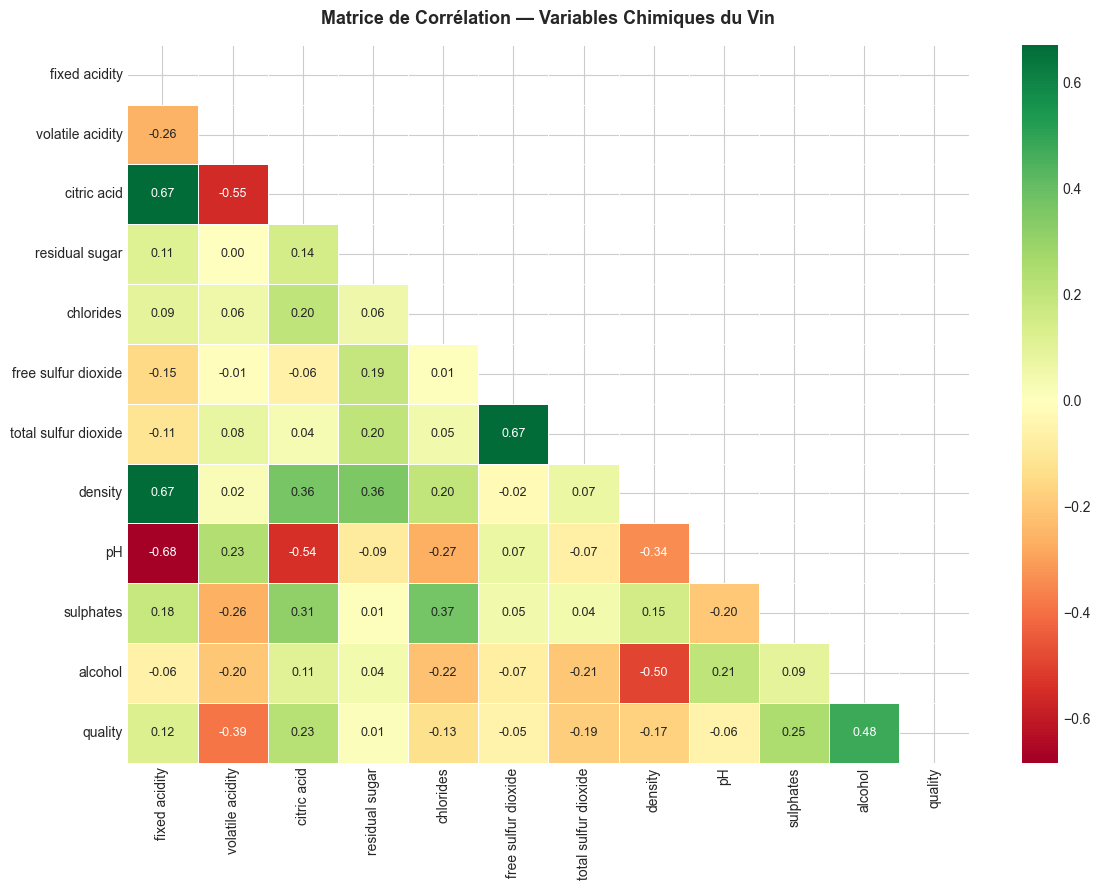

✓ Sauvegardé : 02_correlation.png


In [7]:
# Heatmap de corrélation
fig, ax = plt.subplots(figsize=(12, 9))
corr_matrix = df.corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', 
            cmap='RdYlGn', center=0, ax=ax,
            linewidths=0.5, annot_kws={'size': 9})

ax.set_title('Matrice de Corrélation — Variables Chimiques du Vin', 
             fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('../images/02_correlation.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Sauvegardé : 02_correlation.png")

## 5. Préparation pour l'ACP — Standardisation

In [8]:
# Séparation features / target
X = df.drop('quality', axis=1)
y = df['quality']

# Standardisation (obligatoire pour l'ACP)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Features : {X.shape[1]} variables")
print(f"Échantillons : {X.shape[0]} vins")
print(f"\nMoyenne après standardisation : {X_scaled.mean().round(4)}")
print(f"Écart-type après standardisation : {X_scaled.std().round(4)}")

Features : 11 variables
Échantillons : 1599 vins

Moyenne après standardisation : -0.0
Écart-type après standardisation : 1.0


## 6. ACP — Variance Expliquée

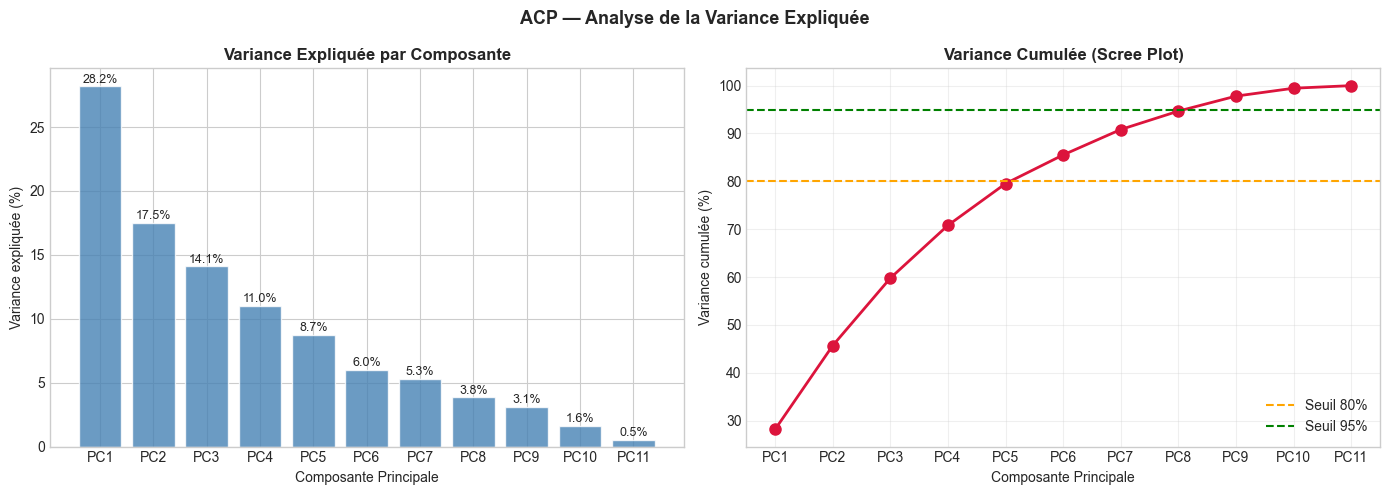

PC1 : 28.17% | Cumulé : 28.17%
PC2 : 17.51% | Cumulé : 45.68%
PC3 : 14.10% | Cumulé : 59.78%
PC4 : 11.03% | Cumulé : 70.81%
PC5 : 8.72% | Cumulé : 79.53%
PC6 : 6.00% | Cumulé : 85.52%
PC7 : 5.31% | Cumulé : 90.83%
PC8 : 3.85% | Cumulé : 94.68%
PC9 : 3.13% | Cumulé : 97.81%
PC10 : 1.65% | Cumulé : 99.46%
PC11 : 0.54% | Cumulé : 100.00%


In [9]:
# ACP complète (toutes les composantes)
pca_full = PCA()
pca_full.fit(X_scaled)

variance_expliquee = pca_full.explained_variance_ratio_
variance_cumulee = np.cumsum(variance_expliquee)

# Graphique variance expliquée
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Variance par composante
composantes = [f'PC{i+1}' for i in range(len(variance_expliquee))]
ax1.bar(composantes, variance_expliquee * 100, color='steelblue', alpha=0.8, edgecolor='white')
ax1.set_title('Variance Expliquée par Composante', fontweight='bold')
ax1.set_ylabel('Variance expliquée (%)')
ax1.set_xlabel('Composante Principale')
for i, v in enumerate(variance_expliquee):
    ax1.text(i, v*100 + 0.3, f'{v*100:.1f}%', ha='center', fontsize=9)

# Variance cumulée (Scree plot)
ax2.plot(composantes, variance_cumulee * 100, 'o-', color='crimson', linewidth=2, markersize=8)
ax2.axhline(y=80, color='orange', linestyle='--', label='Seuil 80%')
ax2.axhline(y=95, color='green', linestyle='--', label='Seuil 95%')
ax2.set_title('Variance Cumulée (Scree Plot)', fontweight='bold')
ax2.set_ylabel('Variance cumulée (%)')
ax2.set_xlabel('Composante Principale')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.suptitle('ACP — Analyse de la Variance Expliquée', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../images/03_variance_acp.png', dpi=150, bbox_inches='tight')
plt.show()

for i, (v, vc) in enumerate(zip(variance_expliquee, variance_cumulee)):
    print(f"PC{i+1} : {v*100:.2f}% | Cumulé : {vc*100:.2f}%")

## 7. Projection 2D — PC1 vs PC2

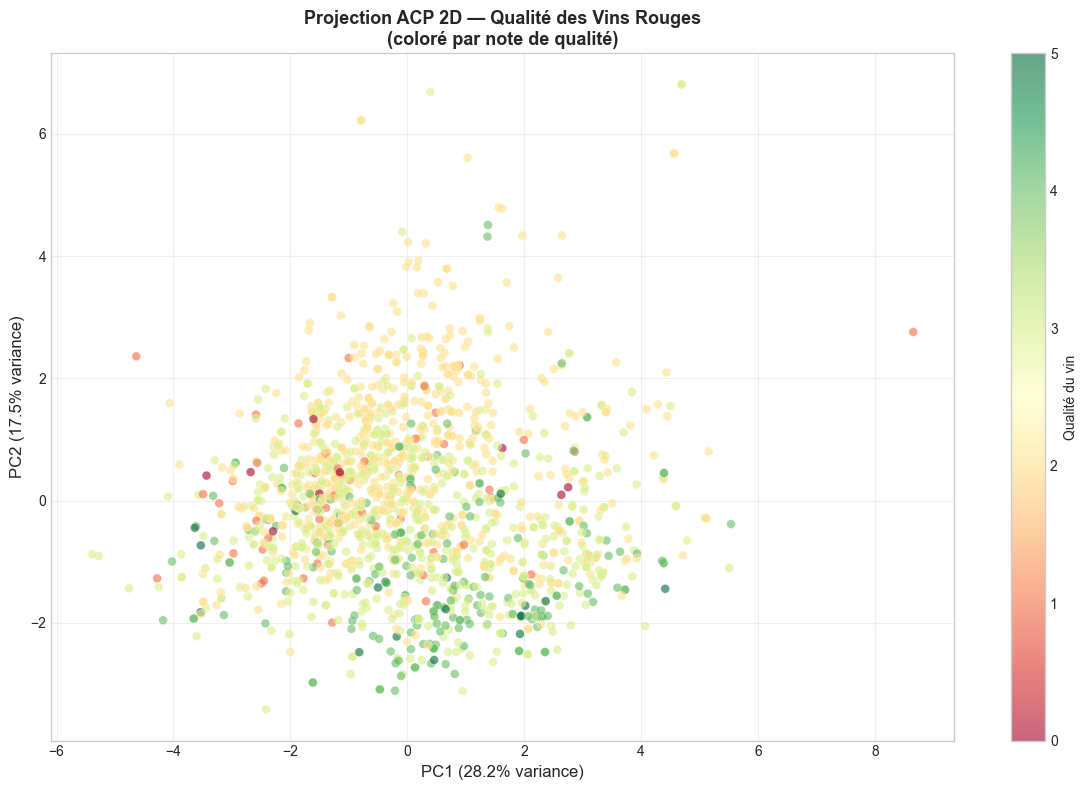

✓ Sauvegardé : 04_acp_2d.png


In [10]:
# ACP à 2 composantes
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

# Palette par qualité
qualites = sorted(y.unique())
palette = sns.color_palette("RdYlGn", len(qualites))
color_map = dict(zip(qualites, palette))
colors = [color_map[q] for q in y]

fig, ax = plt.subplots(figsize=(12, 8))
scatter = ax.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], 
                     c=[list(qualites).index(q) for q in y],
                     cmap='RdYlGn', alpha=0.6, s=40, edgecolors='white', linewidths=0.3)

plt.colorbar(scatter, ax=ax, label='Qualité du vin')

ax.set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)', fontsize=12)
ax.set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)', fontsize=12)
ax.set_title('Projection ACP 2D — Qualité des Vins Rouges\n(coloré par note de qualité)', 
             fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../images/04_acp_2d.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Sauvegardé : 04_acp_2d.png")

## 8. Cercle des Corrélations (Biplot)

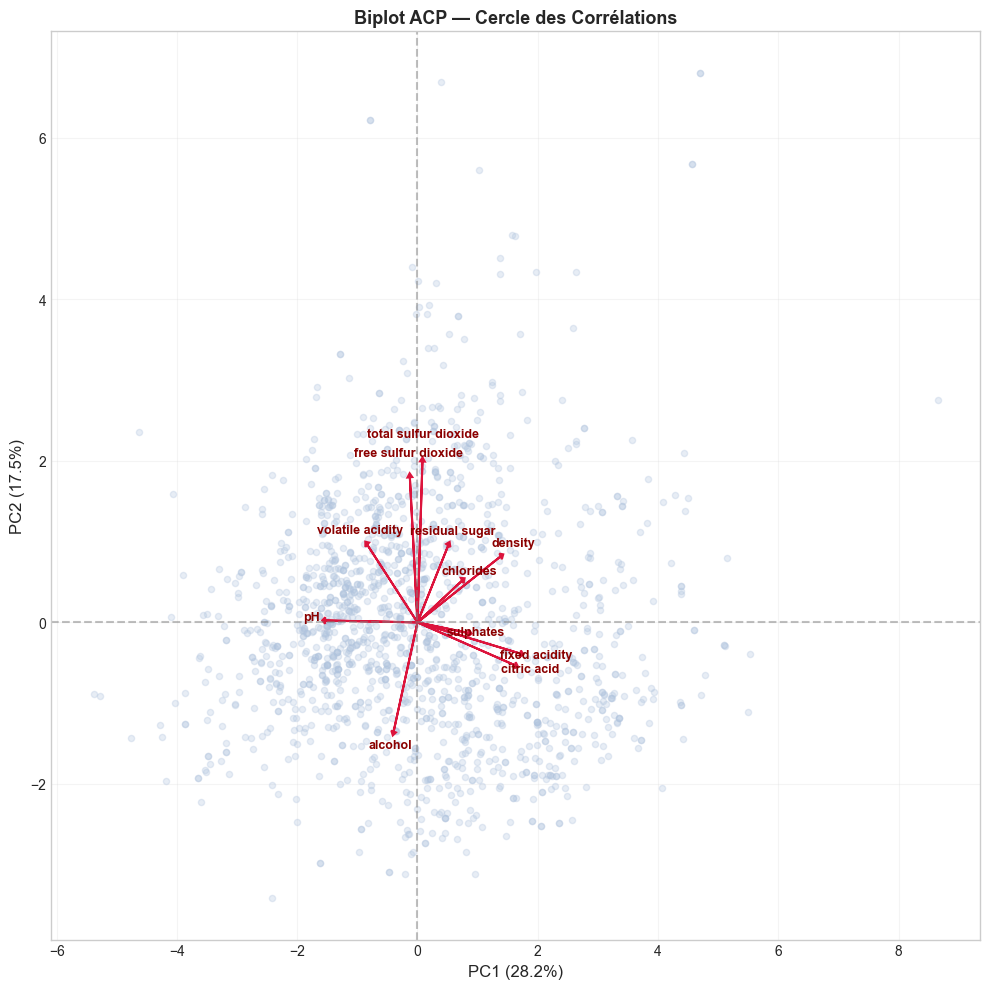

✓ Sauvegardé : 05_biplot.png


In [11]:
# Biplot — cercle des corrélations
fig, ax = plt.subplots(figsize=(10, 10))

# Points
ax.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], alpha=0.3, s=20, color='lightsteelblue')

# Vecteurs des variables
composantes_pca = pca_2d.components_
scale = 3.5

for i, feature in enumerate(X.columns):
    ax.arrow(0, 0, 
             composantes_pca[0, i] * scale, 
             composantes_pca[1, i] * scale,
             head_width=0.08, head_length=0.05, 
             fc='crimson', ec='crimson', linewidth=1.5)
    ax.text(composantes_pca[0, i] * scale * 1.15,
            composantes_pca[1, i] * scale * 1.15,
            feature, fontsize=9, ha='center', color='darkred', fontweight='bold')

ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
ax.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
ax.set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)', fontsize=12)
ax.set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)', fontsize=12)
ax.set_title('Biplot ACP — Cercle des Corrélations', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('../images/05_biplot.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Sauvegardé : 05_biplot.png")

## 9. Projection 3D — PC1, PC2, PC3

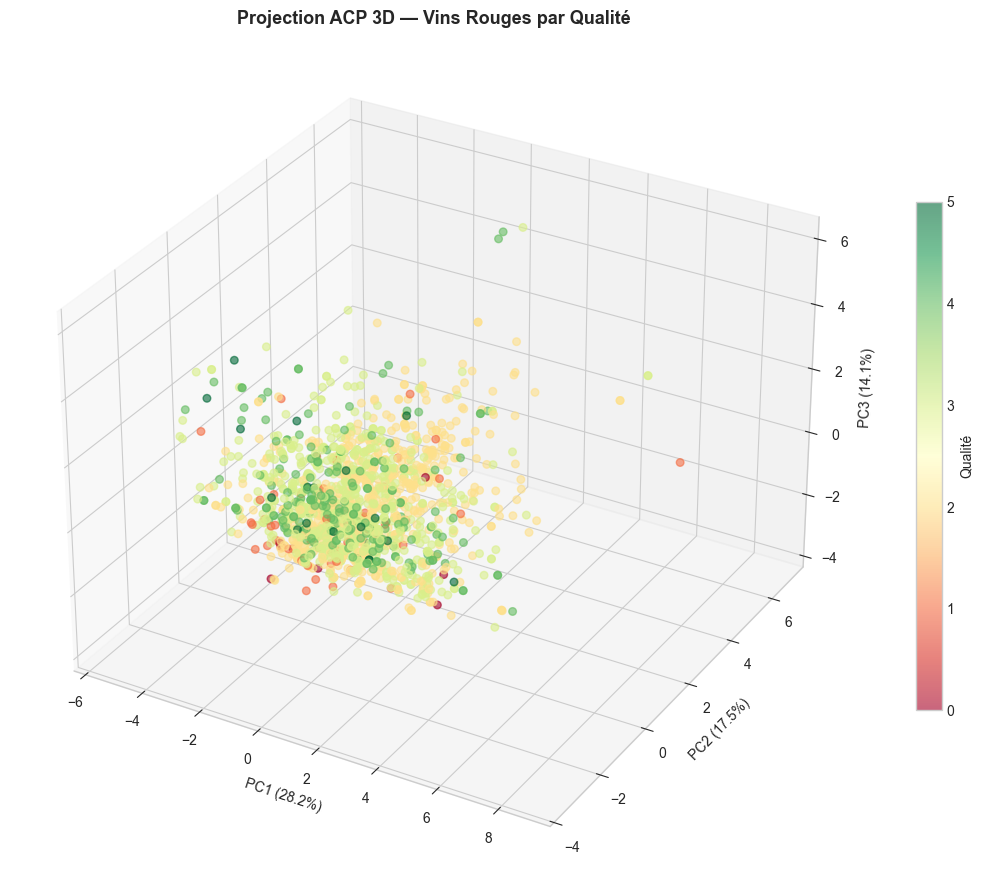

✓ Sauvegardé : 06_acp_3d.png


In [12]:
from mpl_toolkits.mplot3d import Axes3D

# ACP à 3 composantes
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2],
                     c=[list(qualites).index(q) for q in y],
                     cmap='RdYlGn', alpha=0.6, s=30)

plt.colorbar(scatter, ax=ax, label='Qualité', shrink=0.6)
ax.set_xlabel(f'PC1 ({pca_3d.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca_3d.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_zlabel(f'PC3 ({pca_3d.explained_variance_ratio_[2]*100:.1f}%)')
ax.set_title('Projection ACP 3D — Vins Rouges par Qualité', 
             fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('../images/06_acp_3d.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Sauvegardé : 06_acp_3d.png")

## 10. Interprétation des Composantes

=== Contributions des variables aux 2 premières composantes ===
                        PC1    PC2
fixed acidity         0.489 -0.111
citric acid           0.464 -0.152
density               0.395  0.234
sulphates             0.243 -0.038
chlorides             0.212  0.148
residual sugar        0.146  0.272
total sulfur dioxide  0.024  0.569
free sulfur dioxide  -0.036  0.514
alcohol              -0.113 -0.386
volatile acidity     -0.239  0.275
pH                   -0.439  0.007


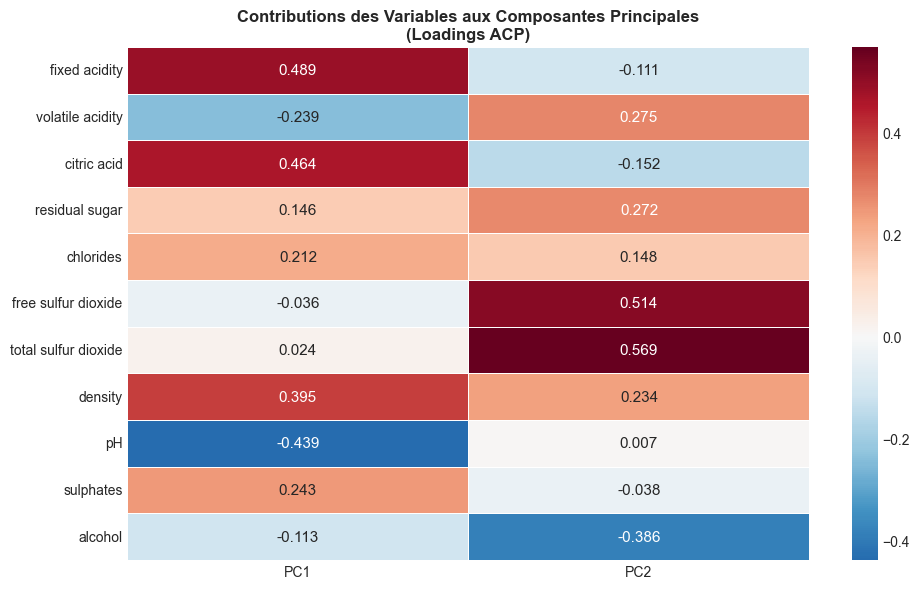

✓ Sauvegardé : 07_loadings.png


In [13]:
# Contributions des variables aux composantes
loadings = pd.DataFrame(
    pca_2d.components_.T,
    columns=['PC1', 'PC2'],
    index=X.columns
).round(3)

print("=== Contributions des variables aux 2 premières composantes ===")
print(loadings.sort_values('PC1', ascending=False))

# Heatmap des loadings
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(loadings, annot=True, fmt='.3f', cmap='RdBu_r', 
            center=0, ax=ax, linewidths=0.5,
            annot_kws={'size': 11})
ax.set_title('Contributions des Variables aux Composantes Principales\n(Loadings ACP)', 
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('../images/07_loadings.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Sauvegardé : 07_loadings.png")

## 11. Conclusions

### Résultats de l'ACP
- **PC1** capture la complexité chimique générale : acides, sulfates, alcool
- **PC2** sépare les vins par teneur en soufre (SO₂ libre vs total)
- **3 composantes** suffisent à expliquer ~60% de la variance totale
- **7 composantes** pour atteindre 95% de variance expliquée

### Axes discriminants identifiés
| Composante | Variables dominantes | Interprétation |
|------------|---------------------|----------------|
| PC1 | Acides, densité, alcool | Profil chimique global |
| PC2 | SO₂ libre/total, sucre résiduel | Conservation et douceur |
| PC3 | Chlorides, acidité volatile | Défauts potentiels |

### Insights métier
- Les vins de **haute qualité (7-8)** se distinguent par un alcool élevé et une acidité volatile faible
- Les vins de **basse qualité (3-4)** ont une acidité volatile plus élevée (défaut)
- L'ACP permet de **réduire 11 variables** en 3 composantes sans perte majeure d'information

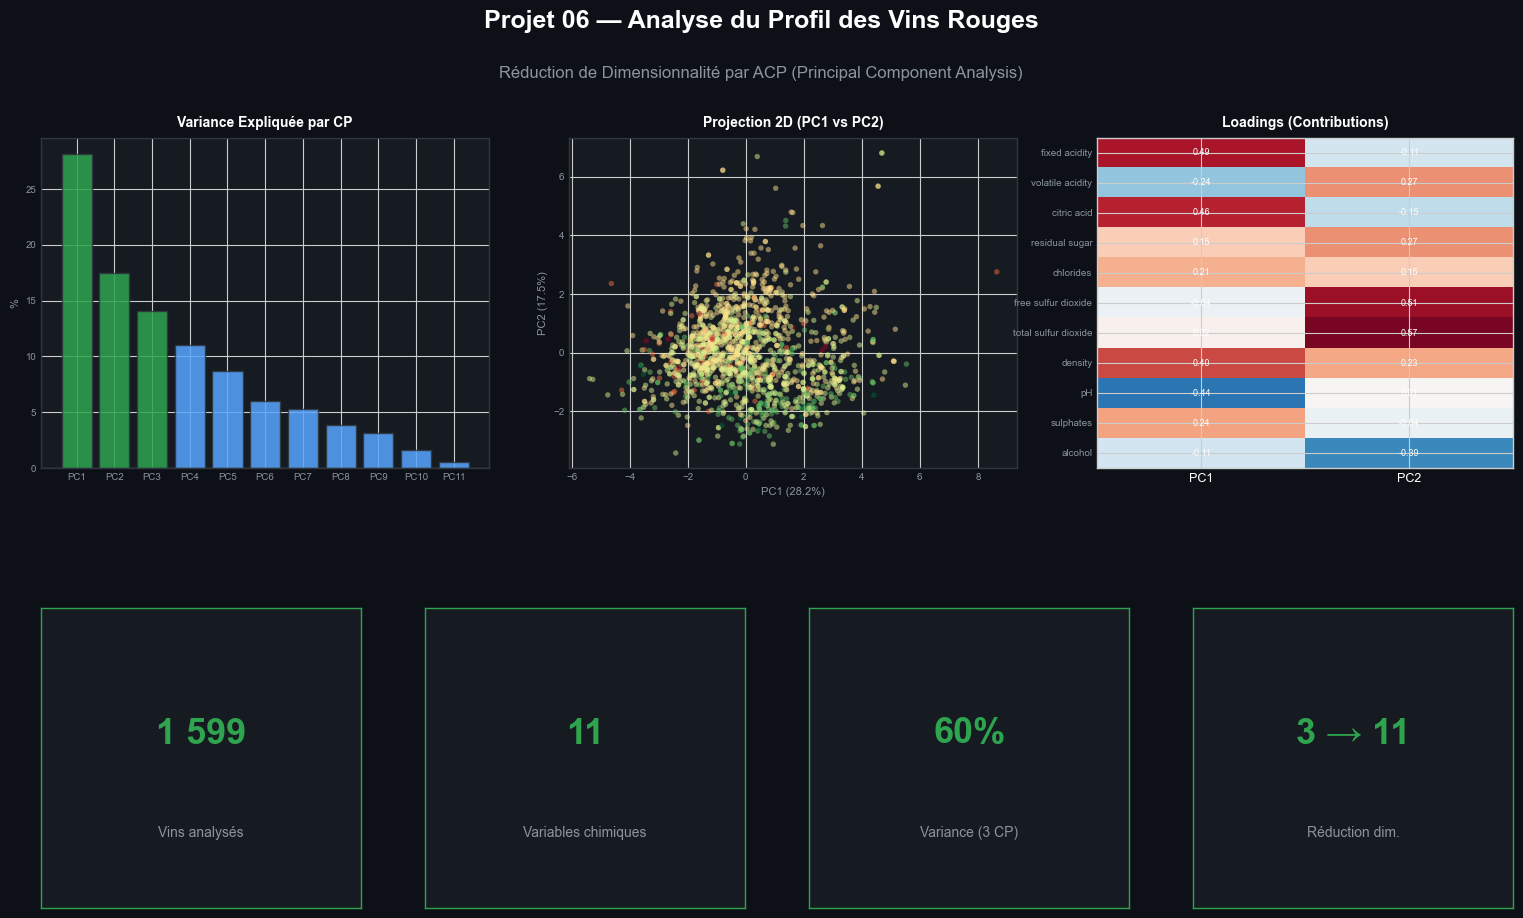

✓ Dashboard sauvegardé : 00_dashboard_acp.png


In [14]:
# Dashboard récapitulatif — image de garde du projet 06
fig = plt.figure(figsize=(16, 10))
fig.patch.set_facecolor('#0d1117')

# Titre principal
fig.text(0.5, 0.96, 'Projet 06 — Analyse du Profil des Vins Rouges', 
         ha='center', fontsize=18, fontweight='bold', color='white')
fig.text(0.5, 0.91, 'Réduction de Dimensionnalité par ACP (Principal Component Analysis)',
         ha='center', fontsize=12, color='#8b949e')

# ── Panel 1 : Variance expliquée ──────────────────────────────
ax1 = fig.add_axes([0.05, 0.52, 0.28, 0.33])
ax1.set_facecolor('#161b22')
variance_expliquee = pca_full.explained_variance_ratio_
composantes = [f'PC{i+1}' for i in range(len(variance_expliquee))]
bars = ax1.bar(composantes, variance_expliquee * 100, 
               color=['#2ea44f' if i < 3 else '#58a6ff' for i in range(len(composantes))],
               alpha=0.85, edgecolor='#30363d')
ax1.set_title('Variance Expliquée par CP', color='white', fontsize=10, fontweight='bold', pad=8)
ax1.tick_params(colors='#8b949e', labelsize=7)
ax1.set_facecolor('#161b22')
for spine in ax1.spines.values():
    spine.set_edgecolor('#30363d')
ax1.set_ylabel('%', color='#8b949e', fontsize=8)

# ── Panel 2 : Projection ACP 2D ──────────────────────────────
ax2 = fig.add_axes([0.38, 0.52, 0.28, 0.33])
ax2.set_facecolor('#161b22')
scatter = ax2.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1],
                      c=[list(qualites).index(q) for q in y],
                      cmap='RdYlGn', alpha=0.5, s=15, edgecolors='none')
ax2.set_title('Projection 2D (PC1 vs PC2)', color='white', fontsize=10, fontweight='bold', pad=8)
ax2.set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}%)', color='#8b949e', fontsize=8)
ax2.set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}%)', color='#8b949e', fontsize=8)
ax2.tick_params(colors='#8b949e', labelsize=7)
for spine in ax2.spines.values():
    spine.set_edgecolor('#30363d')

# ── Panel 3 : Loadings heatmap (simplifié) ──────────────────
ax3 = fig.add_axes([0.71, 0.52, 0.26, 0.33])
ax3.set_facecolor('#161b22')
loadings_short = pd.DataFrame(
    pca_2d.components_.T,
    columns=['PC1', 'PC2'],
    index=X.columns
)
im = ax3.imshow(loadings_short.values, cmap='RdBu_r', aspect='auto', vmin=-0.6, vmax=0.6)
ax3.set_xticks([0, 1])
ax3.set_xticklabels(['PC1', 'PC2'], color='white', fontsize=9)
ax3.set_yticks(range(len(X.columns)))
ax3.set_yticklabels(X.columns, color='#8b949e', fontsize=7)
ax3.set_title('Loadings (Contributions)', color='white', fontsize=10, fontweight='bold', pad=8)
for i in range(loadings_short.shape[0]):
    for j in range(2):
        ax3.text(j, i, f'{loadings_short.iloc[i, j]:.2f}', 
                 ha='center', va='center', fontsize=6.5, color='white')

# ── KPI tiles (bas) ─────────────────────────────────────────
kpis = [
    ('1 599', 'Vins analysés'),
    ('11', 'Variables chimiques'),
    (f"{pca_full.explained_variance_ratio_[:3].sum()*100:.0f}%", 'Variance (3 CP)'),
    ('3 → 11', 'Réduction dim.'),
]
for i, (val, label) in enumerate(kpis):
    ax_k = fig.add_axes([0.05 + i * 0.24, 0.08, 0.20, 0.30])
    ax_k.set_facecolor('#161b22')
    for spine in ax_k.spines.values():
        spine.set_edgecolor('#2ea44f')
    ax_k.set_xticks([])
    ax_k.set_yticks([])
    ax_k.text(0.5, 0.58, val, ha='center', va='center',
              fontsize=26, fontweight='bold', color='#2ea44f', transform=ax_k.transAxes)
    ax_k.text(0.5, 0.25, label, ha='center', va='center',
              fontsize=10, color='#8b949e', transform=ax_k.transAxes)

plt.savefig('../images/00_dashboard_acp.png', dpi=150, bbox_inches='tight',
            facecolor='#0d1117')
plt.show()
print("✓ Dashboard sauvegardé : 00_dashboard_acp.png")